1. Source, access date, observation unit, target and units

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = 'https://raw.githubusercontent.com/fkottas/Teaching-Courses/main/Machine%20Learning%20in%20Finance/2026-2027/lectures/lecture-00-01/data/credit/default_of_credit_card_clients.csv.gz'

credit = pd.read_csv(DATA_URL, compression="gzip")
credit = credit.rename(columns={"default payment next month": "default_next_month"})
credit.head(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


2. Load and audit the credit table

In [2]:
print(credit.shape)
print(credit.dtypes.value_counts())
print(credit.index.is_unique)

(30000, 25)
int64    25
Name: count, dtype: int64
True


In [3]:
audit = pd.Series({'rows': len(credit), 'columns': credit.shape[1], 'missing_cells': int(credit.isna().sum().sum()), 'duplicate_rows': int(credit.duplicated().sum()), 'unique_ids': credit['ID'].nunique()})
audit

,0
rows,30000
columns,25
missing_cells,0
duplicate_rows,0
unique_ids,30000


In [4]:
credit['default_next_month'].value_counts().rename({0: 'No default', 1: 'Default'})

,count
default_next_month,
No default,23364
Default,6636


The table consists of 30,000 rows and 25 integer-coded columns, with a unique index , 30,000 unique client ID's, 0 missing cells, and 0 duplicate rows. Note that integer storage does not mean every variable is numeric in meaning ('SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0' to 'PAY_6' are coded categories). The target variable is imbalanced: 23,364 borrowers (77,885) did not default, whereas 6,636 borrowers (22,12%) defaulted next month.

3. Descriptive statistics

In [5]:
numeric = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2']
summary = credit[numeric].describe().T
summary['IQR'] = summary['75%'] - summary['25%']
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,190000.00
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,13.00
BILL_AMT1,30000.0,51223.33,73635.86,-165580.0,3558.75,22381.5,67091.00,964511.0,63532.25
BILL_AMT2,30000.0,49179.08,71173.77,-69777.0,2984.75,21200.0,64006.25,983931.0,61021.50
PAY_AMT1,30000.0,5663.58,16563.28,0.0,1000.00,2100.0,5006.00,873552.0,4006.00
PAY_AMT2,30000.0,5921.16,23040.87,0.0,833.00,2009.0,5000.00,1684259.0,4167.00


In [6]:
credit['limit_band'] = pd.cut(credit['LIMIT_BAL'], bins=[-np.inf, 100000, 300000, np.inf], labels=['low', 'medium', 'high'])
by_band = credit.groupby('limit_band', observed=False).agg(borrowers=('ID', 'size'), default_rate=('default_next_month', 'mean'), median_age=('AGE', 'median')).round(4)
by_band


,borrowers,default_rate,median_age
limit_band,,,
low,12498,0.2948,32.0
medium,12939,0.1814,34.0
high,4563,0.1326,36.0


In [7]:
credit['age_band'] = pd.cut(credit['AGE'], bins=[20, 30, 40, 50, 80], labels=['21-30', '31-40', '41-50', '51-79'])
pd.pivot_table(credit, index='age_band', columns='limit_band', values='default_next_month', aggfunc='mean', observed=False).round(3)

limit_band,low,medium,high
age_band,,,
21-30,0.287,0.165,0.113
31-40,0.299,0.179,0.124
41-50,0.309,0.195,0.155
51-79,0.297,0.239,0.167


Financial variables (`LIMIT_BAL`, `BILL_AMT1`, `BILL_AMT2`, `PAY_AMT1`, `PAY_AMT2`) are strongly right-skewed (their means are substantially higher than their medians, `50%`). Therefore, the median and interquartile range (`IQR`) provide a more robust summary of central tendency and dispersion than the mean and standard deviation alone. Notice also that bill statements can take negative values (e.g., `-165,580` NT$ in `BILL_AMT1`), reflecting credit balances or overpayments.
Grouping by credit-limit band reveals a clear descriptive pattern across the 30,000 borrowers: the observed default rate is highest in the `low` limit band (**29.48%** across 12,498 borrowers), lower in the `medium` band (**18.14%** across 12,939 borrowers), and lowest in the `high` limit band (**13.26%** across 4,563 borrowers). The pivot table shows that this pattern holds consistently across all age bands.


4. Labels, joins, and derived variables

In [8]:
education_lookup = pd.DataFrame({'EDUCATION': [1, 2, 3, 4], 'education_label': ['graduate school', 'university', 'high school', 'others']})
credit.merge(education_lookup, on='EDUCATION', how='left')[['EDUCATION', 'education_label']].drop_duplicates().sort_values('EDUCATION')

,EDUCATION,education_label
3769,0,NaN
5,1,graduate school
0,2,university
8,3,high school
358,4,others
47,5,NaN
502,6,NaN


In [9]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
payment_cols = [f'PAY_AMT{i}' for i in range(1, 7)]
credit = credit.assign(total_bill=credit[bill_cols].sum(axis=1), total_payment=credit[payment_cols].sum(axis=1))
credit['payment_to_limit'] = credit['total_payment'] / credit['LIMIT_BAL']
credit[['total_bill', 'total_payment', 'payment_to_limit']].describe().round(3)

,total_bill,total_payment,payment_to_limit
count,30000.000,30000.000,30000.000
mean,269861.671,31651.393,0.233
std,379564.331,60827.678,0.316
min,-336259.000,0.000,0.000
25%,28688.000,6679.750,0.068
50%,126311.000,14383.000,0.157
75%,342626.500,33503.500,0.263
max,5263883.000,3764066.000,14.566


5. Visual evidence

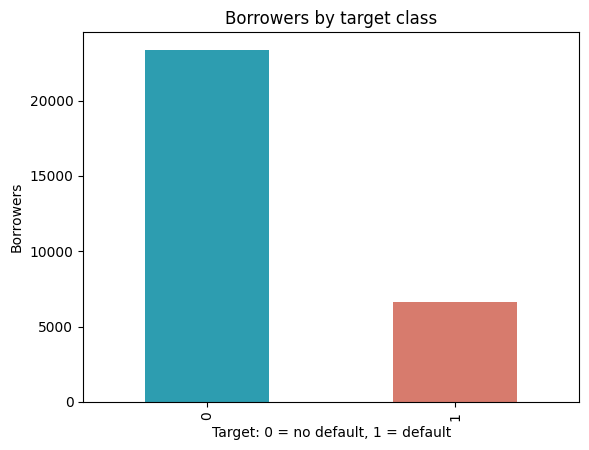

In [10]:
credit['default_next_month'].value_counts().sort_index().plot(kind='bar', color=['#2D9DB0', '#D77B6D'])
plt.title('Borrowers by target class')
plt.xlabel('Target: 0 = no default, 1 = default')
plt.ylabel('Borrowers')
plt.show()

The bar chart illustrates a pronounced class imbalance in the binary target variable across the 30,000 credit-card accounts. Specifically, the majority class comprises 23,364 borrowers, whereas the minority class includes 6,636 borrowers. This visual evidence confirms that raw classification accuracy alone is an inadequate evaluation metric for future supervised-learning models, as a native model predicting exclusively '0' would appear 77,88% accurate without identifying any defaulting clients.

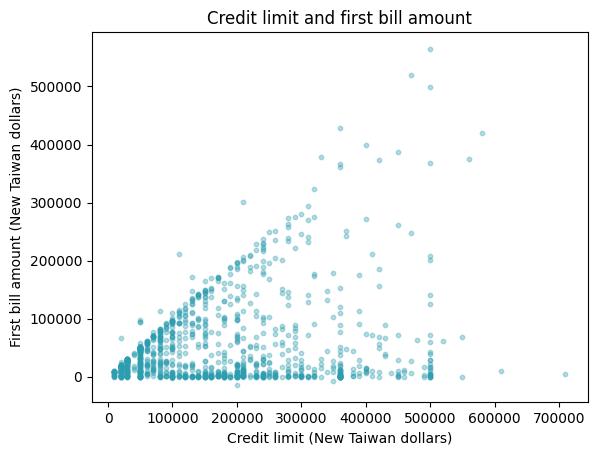

In [11]:
sample = credit.sample(1200, random_state=42)
plt.scatter(sample['LIMIT_BAL'], sample['BILL_AMT1'], s=10, alpha=0.35, color='#2D9DB0')
plt.title('Credit limit and first bill amount')
plt.xlabel('Credit limit (New Taiwan dollars)')
plt.ylabel('First bill amount (New Taiwan dollars)')
plt.show()

The scatter plot of 1,200 randomly sampled borrowers (`random_state=42`) displays a positive association between the granted credit limit (`LIMIT_BAL`) and the first monthly bill statement (`BILL_AMT1`), both measured in New Taiwan dollars (NT$). Most observations are concentrated at lower credit limits and lower bill amounts, reflecting the strong right-skewness of both variables. Furthermore, the upper boundary of bill amounts fans out along a diagonal ceiling as the credit limit increases, because a borrower's monthly balance is naturally constrained by their assigned credit limit, while a few observations lie slightly below zero due to credit balances or overpayments.


In [12]:
credit[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1', 'default_next_month']].corr().round(3)

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1,default_next_month
LIMIT_BAL,1.000,0.145,0.285,0.195,-0.154
AGE,0.145,1.000,0.056,0.026,0.014
BILL_AMT1,0.285,0.056,1.000,0.140,-0.020
PAY_AMT1,0.195,0.026,0.140,1.000,-0.073
default_next_month,-0.154,0.014,-0.020,-0.073,1.000


6. Interpration and limitations

The supplied sample shows a higher default rate among borrowers in the low-limit band (**29.48%**) compared to the high-limit band (**13.26%**), as well as a negative correlation (**-0.154**) between `LIMIT_BAL` and `default_next_month`. This is strictly a descriptive sample association and **not a causal effect**. It does not imply that increasing a borrower's credit limit will cause their probability of default to decrease; rather, it reflects confounding factors such as the bank's underwriting policy, borrower income, creditworthiness, and prior repayment history (since banks assign higher limits to lower-risk clients).

Data-Quality Limitation: Although the dataset contains 0 blank (`NaN`) cells, several categorical variables contain undocumented or special source codes that do not match the standard data dictionary—for example, `EDUCATION` includes unmapped codes (`0`, `5`, `6` appearing as `NaN` after the lookup join) and repayment status columns (`PAY_0` to `PAY_6`) include both negative codes (`-2`, `-1`, `0`) and positive delay codes.

In [13]:
def audit_table(df, target):
    return {'shape': df.shape, 'missing_cells': int(df.isna().sum().sum()), 'duplicate_rows': int(df.duplicated().sum()), 'target_counts': df[target].value_counts().to_dict()}

audit_table(credit, 'default_next_month')


{'shape': (30000, 30),
 'missing_cells': 0,
 'duplicate_rows': 0,
 'target_counts': {0: 23364, 1: 6636}}